## Tugas Praktikum 2: Praproses Data

|     NRP      |     Nama       |
|-----------   |-------------   |
| 5054251013   | Evina Fitriyani| 

## 1. Import Dataset

Dataset diambil dari kompetisi Kaggle House Prices - Advanced Regression Techniques, file yang dipakai cuma train.csv yang berisi 1460 baris dan 81 kolom informasi rumah (ukuran, tahun dibangun, kondisi, dll).

Data set: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data?select=train.csv


In [15]:
# import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option('display.max_columns', None) # untuk melihat semua kolom saat di print

In [16]:
# import dataset train.csv 

df = pd.read_csv('train.csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [17]:
# cek ukuran data, 1460 baris 81 kolom

print(df.shape)

(1460, 81)


In [18]:
# cek tipe data tiap kolom dan jumlah non-null nya

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

## 2. Pembersihan Data

### 2.1 Cek Nilai Yang Hilang

Sebelum data dipakai untuk analisis, dicek dulu kolom mana saja yang punya missing value dan seberapa parah.

In [19]:
# cek jumlah dan persentase nilai hilang tiap kolom

missing = df.isnull().sum()
missing_persen = (missing / len(df)) * 100

missing_df = pd.DataFrame({'jumlah_missing': missing, 'persen_missing': missing_persen})
missing_df = missing_df[missing_df['jumlah_missing'] > 0].sort_values('persen_missing', ascending=False)
missing_df

,jumlah_missing,persen_missing
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


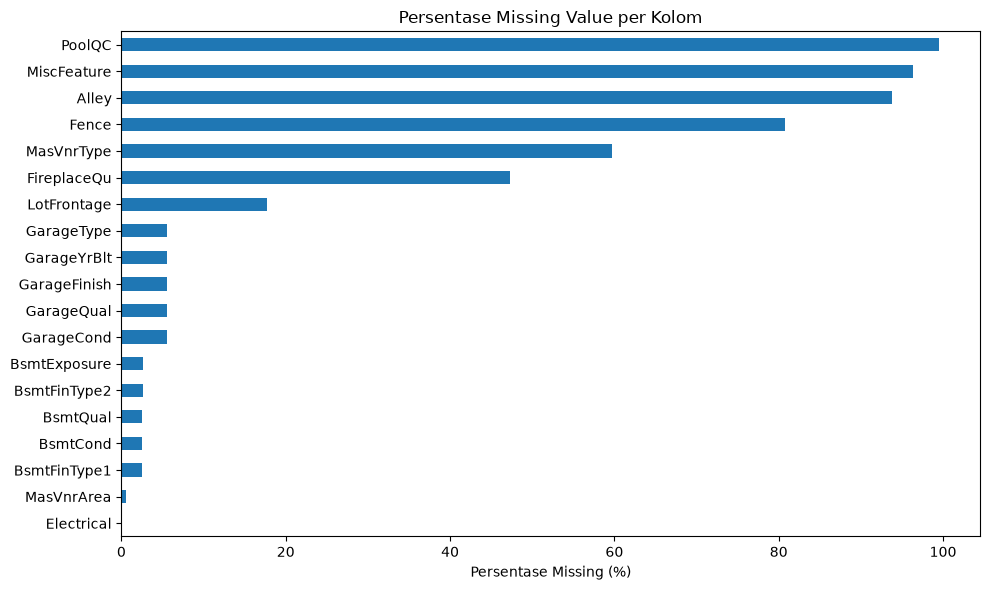

In [20]:
# visualisasi nilai hilang untuk melihat mana yang paling parah 

plt.figure(figsize=(10,6))
missing_df['persen_missing'].plot(kind='barh')
plt.xlabel('Persentase Missing (%)')
plt.title('Persentase Missing Value per Kolom')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 2.2 Hapus Kolom dengan Missing > 50%

Kolom yang missingnya lebih dari setengah baris data dibuang, karena jika dipaksa untuk diisi akan membuat bias di analisis selanjutnya.

In [21]:
# hapus kolom yang nilai hilangnya lebih dari 50%

kolom_dibuang = missing_df[missing_df['persen_missing'] > 50].index.tolist()
print('Kolom yang dibuang:', kolom_dibuang)

df = df.drop(columns=kolom_dibuang)
print('Shape setelah drop kolom:', df.shape)

Kolom yang dibuang: ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']
Shape setelah drop kolom: (1460, 76)


### 2.3 Tangani Missing Value yang Tersisa

Sisa missing value ditangani berbeda-beda sesuai tipe datanya kolom numerik diisi menggunakan median (lebih tahan outlier dibanding mean), kolom kategorikal diisi menggunakan modus.

In [22]:
# cek lagi kolom mana saja yang masih ada missing value

sisa_missing = df.columns[df.isnull().any()].tolist()
print(sisa_missing)

['LotFrontage', 'MasVnrArea', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond']


In [23]:
# isi missing value numerik dengan median, kategorikal dengan modus

for kolom in sisa_missing:
    if pd.api.types.is_numeric_dtype(df[kolom]):
        df[kolom] = df[kolom].fillna(df[kolom].median())  # numerik pakai median
    else:
        df[kolom] = df[kolom].fillna(df[kolom].mode()[0])  # teks/kategorikal pakai modus

print('Total missing value sekarang:', df.isnull().sum().sum())

Total missing value sekarang: 0


## 3. Deteksi dan Penanganan Outlier

Deteksi Outlier dilakukan menggunakan bloxplot di beberapa atribut numerik yang penting

In [24]:
# ambil kolom numerik saja (kecuali Id)

kolom_numerik = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
kolom_numerik.remove('Id')
print(kolom_numerik)

['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


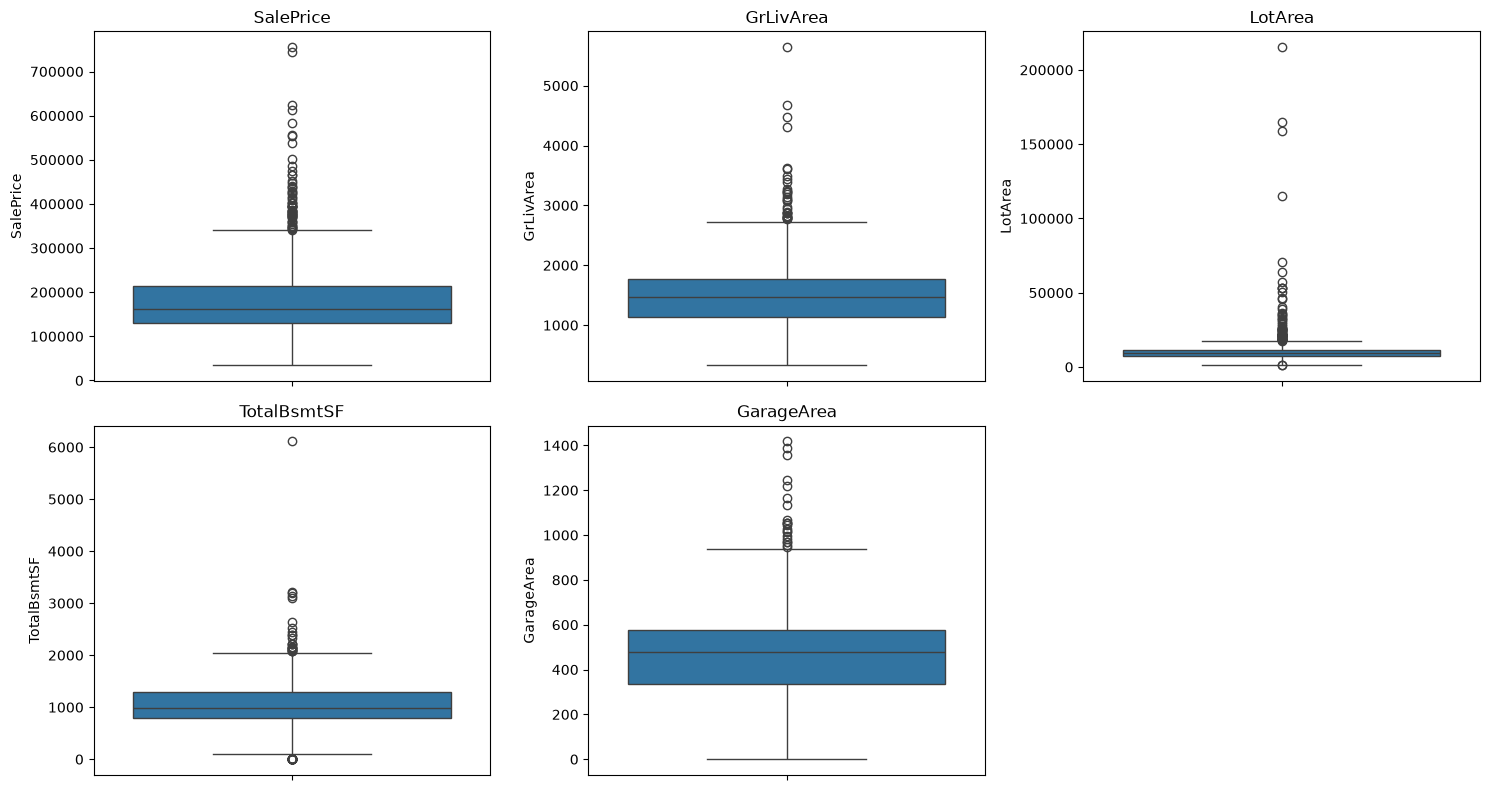

In [25]:
# boxplot beberapa atribut numerik penting untuk cek outlier

kolom_cek = ['SalePrice', 'GrLivArea', 'LotArea', 'TotalBsmtSF', 'GarageArea']

plt.figure(figsize=(15,8))
for i, kolom in enumerate(kolom_cek):
    plt.subplot(2, 3, i+1)
    sns.boxplot(y=df[kolom])
    plt.title(kolom)
plt.tight_layout()
plt.show()

Dari boxplot kelihatan ada outlier di beberapa atribut kayak GrLivArea, LotArea, sama SalePrice. Outlier di sini nggak langsung dihapus semua karena bisa jadi rumah yang emang besar/mahal beneran (bukan data error), jadi dipakai metode capping (IQR) agar nilai ekstrem dibatasi tapi datanya tidak hilang.

In [26]:
# tangani outlier dengan metode IQR capping (batas atas/bawah)

def cap_outlier(kolom):
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    df[kolom] = np.where(df[kolom] > batas_atas, batas_atas,
                  np.where(df[kolom] < batas_bawah, batas_bawah, df[kolom]))

for kolom in kolom_numerik:
    cap_outlier(kolom)

print('Outlier sudah di-cap')

Outlier sudah di-cap


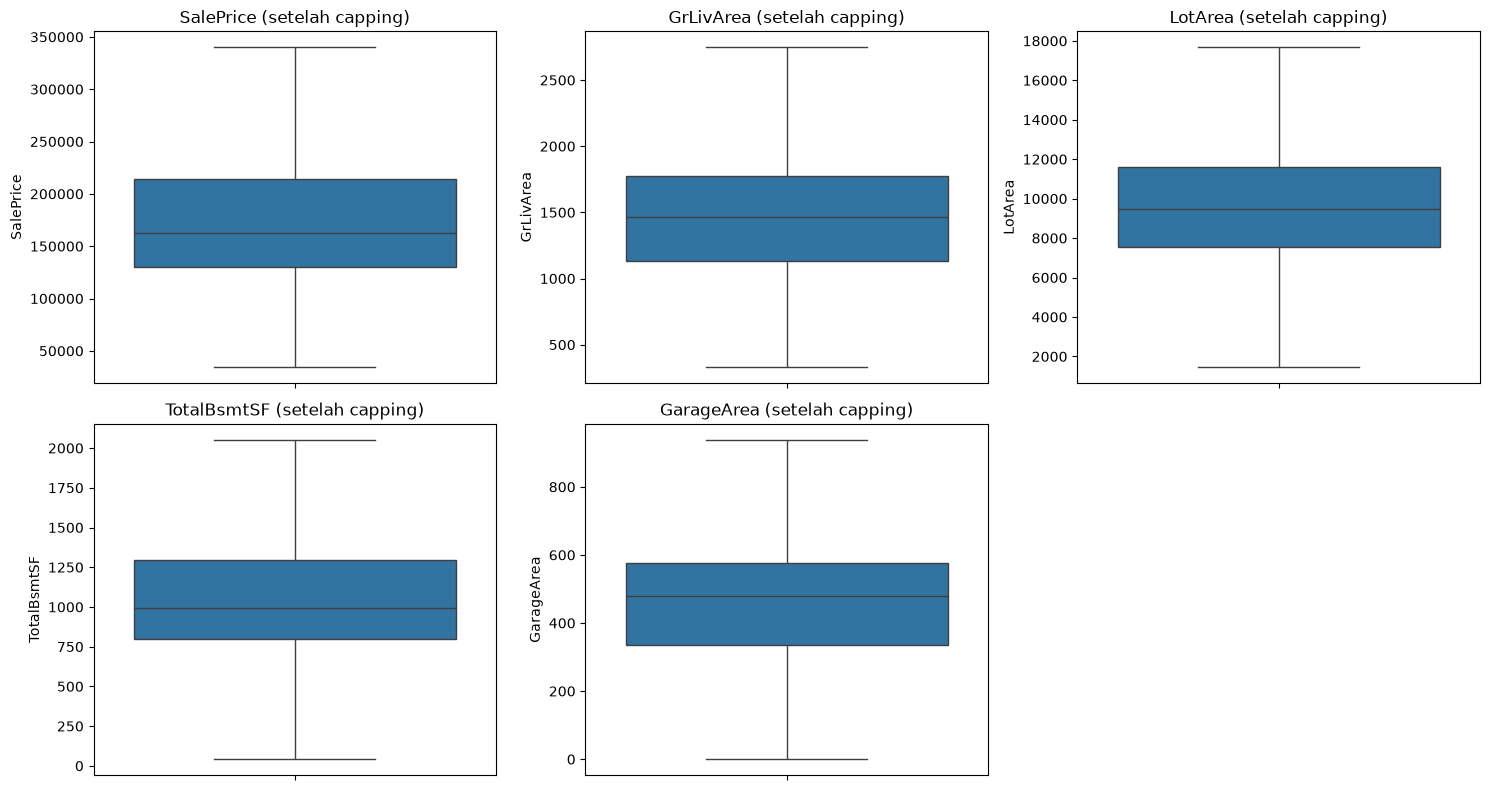

In [27]:
# cek ulang boxplot setelah capping

plt.figure(figsize=(15,8))
for i, kolom in enumerate(kolom_cek):
    plt.subplot(2, 3, i+1)
    sns.boxplot(y=df[kolom])
    plt.title(kolom + ' (setelah capping)')
plt.tight_layout()
plt.show()

In [28]:
# simpan dataset hasil cleaning (sebelum transformasi/PCA) buat dikumpul

df.to_csv('5054251013_Evina_Fitriyani_Tugas_Praproses_Data.csv', index=False)
print('Dataset hasil cleaning berhasil disimpan')
print('Shape:', df.shape)

Dataset hasil cleaning berhasil disimpan
Shape: (1460, 76)


## 4. Transformasi Data

### 4.1 Normalisasi/Standarisasi

Atrubut numerik distndarisasi agar semua fitur memiliki skala yang sebanding, kecuali SalePrice yang dibiarkan apa adanya karena itu target/label

In [29]:
# standarisasi kolom numerik (kecuali Id dan target SalePrice)

kolom_scale = [k for k in kolom_numerik if k != 'SalePrice']

scaler = StandardScaler()
df[kolom_scale] = scaler.fit_transform(df[kolom_scale])

df[kolom_scale].head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
0,0.131067,-0.237456,-0.333244,0.652644,-0.564161,1.053246,0.878668,0.795643,0.614224,0.0,-0.958790,-0.488321,-0.830489,1.164283,0.0,0.428636,1.111765,0.0,0.789741,1.227585,0.195307,0.0,0.981148,-0.957043,1.017824,0.315946,0.373509,-0.787243,0.350520,0.0,0.0,0.0,0.0,0.0,-1.599111,0.138777
1,-0.935733,0.633321,-0.013189,-0.073068,2.030907,0.156179,-0.429577,-0.667353,1.242296,0.0,-0.648290,0.532289,0.289638,-0.796041,0.0,-0.502349,-0.821739,0.0,0.789741,-0.761621,0.195307,0.0,-0.316385,0.608540,-0.108062,0.315946,-0.051541,1.768105,-0.811747,0.0,0.0,0.0,0.0,0.0,-0.489110,-0.614439
2,0.131067,-0.063300,0.446022,0.652644,-0.564161,0.986797,0.830215,0.541858,0.106224,0.0,-0.300716,-0.327437,-0.653917,1.191828,0.0,0.586571,1.111765,0.0,0.789741,1.227585,0.195307,0.0,-0.316385,0.608540,0.934425,0.315946,0.663315,-0.787243,-0.011497,0.0,0.0,0.0,0.0,0.0,0.990891,0.138777
3,0.397766,-0.527714,-0.027104,0.652644,-0.564161,-1.870528,-0.720298,-0.667353,-0.517230,0.0,-0.055097,-0.739702,-0.540801,0.939328,0.0,0.443182,1.111765,0.0,-1.026041,-0.761621,0.195307,0.0,0.332382,0.608540,0.809327,1.662750,0.827539,-0.787243,-0.144872,0.0,0.0,0.0,0.0,0.0,-1.599111,-1.367655
4,0.131067,0.865528,1.283733,1.378355,-0.564161,0.953572,0.733308,1.945140,0.496460,0.0,-0.170955,0.238172,-0.033157,1.621080,0.0,1.442744,1.111765,0.0,0.789741,1.227585,1.512385,0.0,1.629914,0.608540,0.892726,1.662750,1.764579,0.859156,0.788753,0.0,0.0,0.0,0.0,0.0,2.100892,0.138777


### 4.2 One-Hot Encoding

Atribut Kategroikal diubah menjadi numerik menggunkan one-hot encoding agar bisa dipakai model machine learning

In [30]:
# lihat kolom kategorikal

kolom_kategori = df.select_dtypes(include='object').columns.tolist()
print(len(kolom_kategori), 'kolom kategorikal')
print(kolom_kategori)

38 kolom kategorikal
['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']


C:\Users\ACER\AppData\Local\Temp\ipykernel_15760\1868282957.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kolom_kategori = df.select_dtypes(include='object').columns.tolist()


In [31]:
# one-hot encoding untuk semua kolom kategorikal

df_encoded = pd.get_dummies(df, columns=kolom_kategori, drop_first=True)
print('Shape sebelum encoding:', df.shape)
print('Shape setelah encoding:', df_encoded.shape)

Shape sebelum encoding: (1460, 76)
Shape setelah encoding: (1460, 235)


## 5. Reduksi Dimensi

### 5.1 Analisis Korelasi

Korelasi dicek antar atribut numerik asli untuk menemukan pasagan atribut yang informasinya mirip

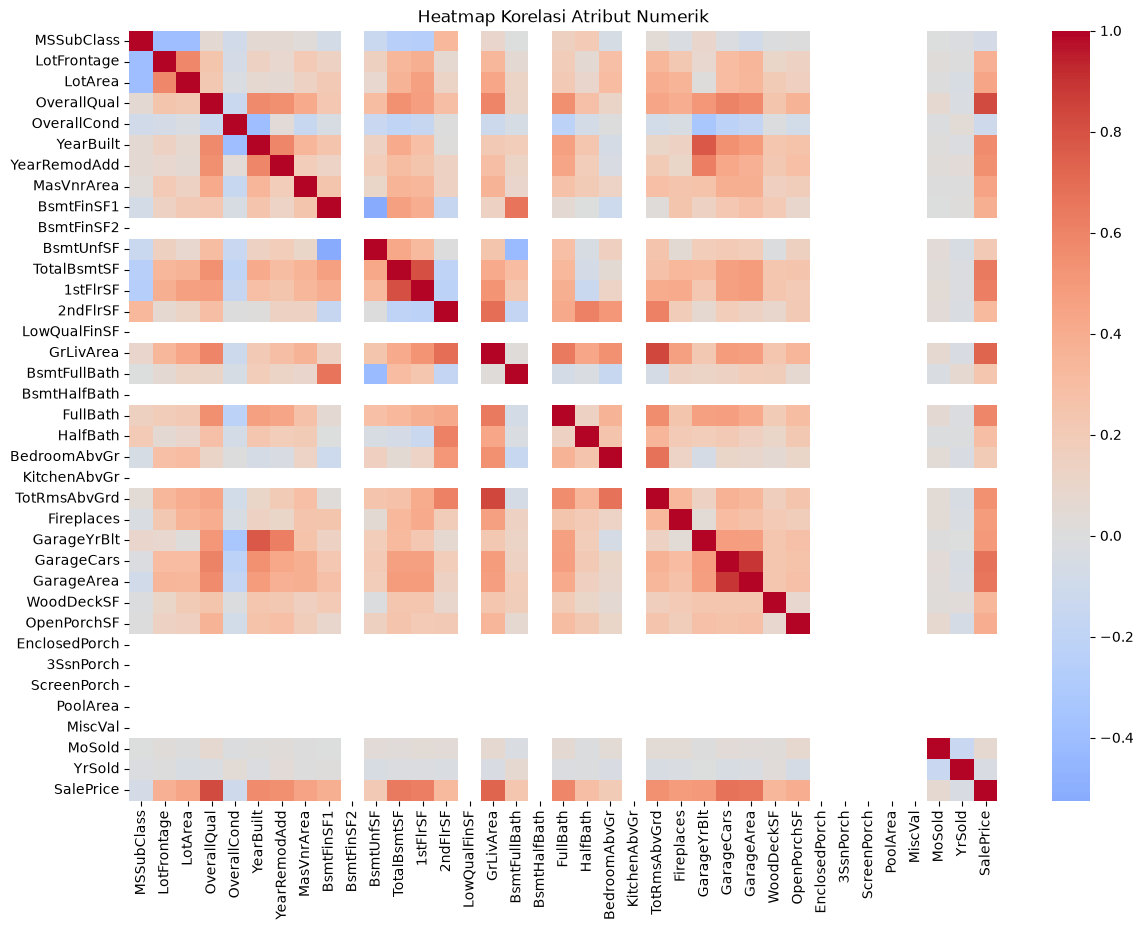

In [32]:
# cek korelasi antar atribut numerik asli (sebelum one-hot)

korelasi = df[kolom_numerik].corr()

plt.figure(figsize=(14,10))
sns.heatmap(korelasi, cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi Atribut Numerik')
plt.show()

In [33]:
# cari pasangan atribut yang korelasinya sangat tinggi (> 0.8)

pasangan_tinggi = []
for i in range(len(korelasi.columns)):
    for j in range(i):
        if abs(korelasi.iloc[i, j]) > 0.8:
            pasangan_tinggi.append((korelasi.columns[i], korelasi.columns[j], korelasi.iloc[i, j]))

pasangan_tinggi

[('1stFlrSF', 'TotalBsmtSF', np.float64(0.8071577034861679)),
 ('TotRmsAbvGrd', 'GrLivArea', np.float64(0.8351922143575267)),
 ('GarageArea', 'GarageCars', np.float64(0.89455968020865)),
 ('SalePrice', 'OverallQual', np.float64(0.8176804345556551))]

In [34]:
# buang salah satu dari tiap pasangan yang korelasinya tinggi

kolom_dibuang_korelasi = [pasangan[0] for pasangan in pasangan_tinggi]
kolom_dibuang_korelasi = list(set(kolom_dibuang_korelasi))
kolom_dibuang_korelasi = [k for k in kolom_dibuang_korelasi if k != 'SalePrice']  # target jangan ikut dibuang
print('Kolom yang dibuang karena korelasi tinggi:', kolom_dibuang_korelasi)

df_encoded = df_encoded.drop(columns=kolom_dibuang_korelasi)
print('Shape setelah buang kolom korelasi tinggi:', df_encoded.shape)

Kolom yang dibuang karena korelasi tinggi: ['GarageArea', '1stFlrSF', 'TotRmsAbvGrd']
Shape setelah buang kolom korelasi tinggi: (1460, 232)


### 5.2 PCA (principal Component Analysis)

PCA digunakan untuk reduksi dimensi akhir, ambil komponen yang bisa menjelaskan 95% variansi data agar informasi pentignya tetap kepegang meski jumlah fiturnya berkurang banyak

In [35]:
# pisahkan fitur (X) dan target (y) sebelum PCA

X = df_encoded.drop(columns=['Id', 'SalePrice'])
y = df_encoded['SalePrice']

# ambil komponen yang menjelaskan 95% variansi data
pca = PCA(n_components=0.95)  
X_pca = pca.fit_transform(X)

print('Jumlah fitur sebelum PCA:', X.shape[1])
print('Jumlah komponen setelah PCA:', X_pca.shape[1])

Jumlah fitur sebelum PCA: 230
Jumlah komponen setelah PCA: 65


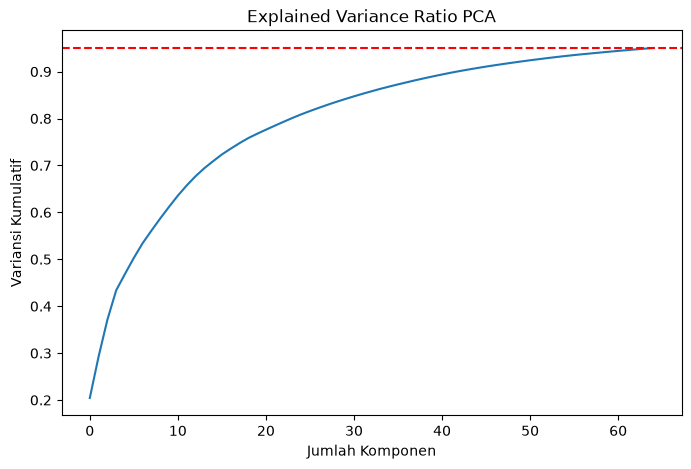

In [36]:
# visualisasi variansi kumulatif PCA

plt.figure(figsize=(8,5))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Jumlah Komponen')
plt.ylabel('Variansi Kumulatif')
plt.title('Explained Variance Ratio PCA')
plt.axhline(y=0.95, color='r', linestyle='--')
plt.show()

## 6. Dataset Akhir

In [37]:
# gabungkan hasil PCA dengan target jadi dataset akhir

kolom_pca = [f'PC{i+1}' for i in range(X_pca.shape[1])]
df_final = pd.DataFrame(X_pca, columns=kolom_pca)
df_final['SalePrice'] = y.values

df_final.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46,PC47,PC48,PC49,PC50,PC51,PC52,PC53,PC54,PC55,PC56,PC57,PC58,PC59,PC60,PC61,PC62,PC63,PC64,PC65,SalePrice
0,2.430233,0.260611,-1.599412,-1.798784,0.883164,-1.762907,-0.506578,-1.442465,-0.626521,-0.344102,-1.038935,-0.220583,-0.006562,0.471135,-0.873323,-0.229260,-0.165870,0.040126,-0.836830,-0.219049,-0.080279,0.090862,-0.412045,0.387716,-0.026331,0.073407,0.347884,-0.247138,0.284819,0.132736,0.153862,0.045890,-0.232683,-0.081934,-0.074381,-0.033476,0.048096,0.128322,0.185314,0.090810,0.104860,0.037803,0.170552,0.061829,0.078418,0.168164,0.024960,0.240611,0.024693,-0.398416,-0.120110,-0.232086,-0.154762,0.284177,-0.068735,-0.039207,0.004735,0.003680,-0.180683,0.012607,0.110172,-0.101877,-0.060429,-0.048376,0.000431,208500.0
1,-0.141502,-1.442216,1.481287,-0.009761,1.099381,0.873410,0.044816,1.867514,0.640850,-0.338278,-1.065612,0.019912,-1.329773,-0.672678,0.292557,0.692003,-0.911810,-1.289481,-0.292338,-0.368829,1.234926,0.479961,0.856404,0.195645,-0.176161,-0.133803,0.157719,0.609216,-0.839121,-0.530191,0.291086,-0.256710,-0.131371,-0.149280,0.103977,0.898586,-0.062797,1.131130,0.400476,0.020016,-0.707014,0.334655,0.037681,-0.528435,-0.449635,0.110869,-0.609373,-0.379808,-0.269201,-0.150369,0.046921,-0.270608,-0.074217,-0.094068,-0.325961,0.050760,-0.232108,-0.024527,0.308696,0.163229,-0.327527,0.653952,-0.109114,0.035747,-0.198866,181500.0
2,2.998348,0.560550,-0.649765,-1.345754,0.010514,-0.378814,-1.145722,-0.299037,-0.003102,0.277661,0.812795,-1.302176,-0.241615,0.536265,-0.619135,-0.451778,0.132041,0.949603,-0.975932,-0.154417,0.088474,0.028847,0.079477,0.318718,-0.039664,0.058680,0.113706,-0.101023,-0.007220,0.224322,0.116655,-0.698632,0.053662,-0.333824,-0.242821,0.069022,-0.021039,0.468636,-0.617326,-0.052055,-0.103794,0.119319,-0.293529,0.580053,0.274467,0.113137,0.056857,0.459248,0.232885,0.125519,0.144761,-0.334362,0.066352,0.414143,0.006039,-0.132549,-0.006985,-0.069618,-0.009284,-0.151615,0.061839,-0.186517,-0.027925,-0.134473,0.050951,223500.0
3,-0.575073,0.977255,0.342536,-0.616439,-0.559435,0.197803,0.171172,-0.647609,-0.046881,-2.272164,-1.151512,-0.851897,1.489891,-0.406007,0.011362,0.942081,-0.427302,1.176261,0.409135,0.910063,-1.016286,0.406755,0.373637,0.319476,0.530973,1.439408,-0.447270,0.667619,0.801727,-0.192434,-0.520462,-0.044777,0.471775,0.515816,0.104452,-0.899716,0.074860,0.006676,0.605544,0.220770,0.378775,-0.945967,1.000519,1.055118,0.066013,0.258225,0.334683,-0.183655,-0.122948,0.132383,-0.210939,0.211520,0.096400,0.782078,-0.247506,-0.295410,0.855359,-0.176827,0.285280,-0.066096,-0.199672,-0.093689,-0.633909,0.378188,-0.014386,140000.0
4,5.023555,1.006597,1.139949,-1.323301,-0.459013,0.090567,-1.170222,0.246616,-0.311150,1.603101,0.572766,-0.160259,0.496183,-0.197137,-0.444475,-0.108743,-0.165416,1.331624,-1.148512,0.318058,0.094196,-0.202819,0.241574,-0.044859,-0.148352,0.208653,0.056356,0.411092,-0.005950,-0.467476,0.412236,-0.042934,-0.035677,0.046744,0.063682,0.115766,0.005853,0.404952,-0.451274,-0.071040,0.067504,0.081347,0.071086,0.176307,0.055619,0.272082,0.078873,-0.002503,0.151483,0.100675,0.290150,0.003434,-0.068554,-0.021716,0.120110,-0.054431,-0.073249,-0.092032,0.351682,-0.087335,-0.257962,0.155911,0.163905,-0.048951,-0.110069,250000.0


In [39]:
print('Shape dataset akhir setelah PCA:', df_final.shape)

Shape dataset akhir setelah PCA: (1460, 66)


## Ringkasan
- Dataset awal: 1460 baris, 81 kolom
- Kolom dengan missing value > 50% dibuang
- Sisa missing value ditangani dengan median (numerik) dan modus (kategorikal)
- Outlier ditangani dengan IQR capping, bukan dihapus, biar data rumah mahal/besar tetap kepakai
- Atribut numerik distandarisasi, atribut kategorikal di-one-hot encoding
- Atribut dengan korelasi tinggi (>0.8) dibuang salah satunya
- PCA dipakai untuk reduksi dimensi akhir, menjelaskan 95% variansi data

### Laporan Analisis

#### Deskripsi Dataset
Dataset ini diambil dari Kaggle House Prices - Advanced Regression Techniques, file train.csv, terdiri dari 1460 baris dan 81 kolom informasi rumah kayak ukuran, tahun dibangun, kualitas, sampai harga jual (SalePrice) sebagai target.

#### Pembersihan Data
Ada 19 kolom yang punya missing value, mulai dari 0,07% (Electrical) sampai 99,52% (PoolQC). Kolom PoolQC, MiscFeature, Alley, Fence, dan MasVnrType dibuang karena missingnya di atas 50%, sehingga shape berkurang jadi (1460, 76). Sisa 14 kolom yang masih ada missing value ditangani dengan median untuk kolom numerik dan modus untuk kolom kategorikal, sampai akhirnya total missing value jadi 0.

#### Deteksi dan Penanganan Outlier
Dari boxplot atribut SalePrice, GrLivArea, LotArea, TotalBsmtSF, dan GarageArea, keliatan banyak titik di luar whisker yang menandakan outlier, terutama di LotArea yang rentangnya sampai ratusan ribu. Outlier ditangani pakai metode IQR capping, bukan dihapus, karena nilai ekstrem itu kemungkinan besar emang rumah yang beneran besar/mahal, bukan kesalahan input. Setelah capping, boxplot jadi lebih rapat dan whisker-nya lebih pendek, artinya sebaran datanya udah lebih terkendali tanpa kehilangan baris data.

#### Transformasi Data
Atribut numerik (kecuali SalePrice) distandarisasi pakai StandardScaler biar semua fitur punya skala yang sebanding. Untuk atribut kategorikal, ada 38 kolom yang di-one-hot encoding, sehingga jumlah kolom bertambah dari 76 jadi 235.

#### Reduksi Dimensi
Dari heatmap korelasi, ditemukan 4 pasangan atribut dengan korelasi di atas 0,8: 1stFlrSF-TotalBsmtSF (0,81), TotRmsAbvGrd-GrLivArea (0,84), GarageArea-GarageCars (0,89), dan SalePrice-OverallQual (0,82). Tiga pasangan pertama dibuang salah satunya (GarageArea, 1stFlrSF, TotRmsAbvGrd) karena redundan, sedangkan pasangan SalePrice-OverallQual dipertahankan karena SalePrice adalah target. Shape setelah ini jadi (1460, 232). Selanjutnya PCA diterapkan pada 230 fitur (di luar Id dan SalePrice), menghasilkan 65 komponen utama yang mampu menjelaskan 95% variansi data artinya jumlah fitur berhasil dipangkas sekitar 72% tanpa banyak kehilangan informasi.

#### Ringkasan Dataset Akhir
Dataset yang dikumpulkan sebagai output (csv) adalah hasil setelah tahap cleaning, dengan shape (1460, 76), sudah bebas missing value dan outlier sudah ditangani lewat capping. Tahap normalisasi, encoding, dan PCA tetap dilakukan di notebook sebagai bagian dari analisis, menghasilkan 65 komponen PCA yang siap dipakai untuk pemodelan lebih lanjut.